Use Case 4 – SQL Analysis and Integration.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3

from pathlib import Path

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Connect to the existing chicago_crime.db database

In [ ]:
PROJECT_DIR = Path.cwd().parent

DATABASE_FILE = (
    PROJECT_DIR / "database" / "chicago_crime.db"
)

print("Database exists:", DATABASE_FILE.exists())

connection = sqlite3.connect(DATABASE_FILE)

print("Connected to SQLite database successfully!")

Before writing SQL queries, let's confirm that our tables exist.

In [ ]:
tables_query = """
SELECT name
FROM sqlite_master
WHERE type = 'table'
ORDER BY name;
"""

tables_df = pd.read_sql_query(
    tables_query,
    connection
)

display(tables_df)

Verify the crime record count

In [ ]:
crime_count_query = """
SELECT COUNT(*) AS Total_Crime_Records
FROM chicago_crime;
"""

crime_count_df = pd.read_sql_query(
    crime_count_query,
    connection
)

display(crime_count_df)

Annual crime counts using SQL

In [ ]:
# SQL query: Annual crime counts

yearly_crime_query = """
SELECT
    year AS Year,
    COUNT(*) AS Total_Crimes
FROM chicago_crime
GROUP BY year
ORDER BY year;
"""

yearly_crime_sql = pd.read_sql_query(
    yearly_crime_query,
    connection
)

display(yearly_crime_sql)

Top five crime categories and percentages
We will join the main crime table with the IUCR reference table.

In [ ]:


top_categories_query = """
SELECT
    i.PRIMARY_TYPE AS Crime_Category,
    COUNT(*) AS Crime_Count,
    ROUND(
        COUNT(*) * 100.0 /
        (SELECT COUNT(*) FROM chicago_crime),
        2
    ) AS Percentage
FROM chicago_crime AS c
JOIN iucr AS i
    ON c.iucr_code = i.IUCR
GROUP BY i.PRIMARY_TYPE
ORDER BY Crime_Count DESC
LIMIT 5;
"""

top_categories_sql = pd.read_sql_query(
    top_categories_query,
    connection
)

display(top_categories_sql)

Annual arrest counts using SQL

In [ ]:

yearly_arrest_query = """
SELECT
    year AS Year,
    COUNT(*) AS Total_Crimes,
    SUM(CASE WHEN arrest = 1 THEN 1 ELSE 0 END)
        AS Total_Arrests,
    ROUND(
        SUM(CASE WHEN arrest = 1 THEN 1 ELSE 0 END)
        * 100.0 / COUNT(*),
        2
    ) AS Arrest_Rate
FROM chicago_crime
GROUP BY year
ORDER BY year;
"""

yearly_arrest_sql = pd.read_sql_query(
    yearly_arrest_query,
    connection
)

display(yearly_arrest_sql)

Create yearly crime summary view ( vw_crime_yearly )


In [ ]:

connection.execute("""
CREATE VIEW IF NOT EXISTS vw_crime_yearly AS
SELECT
    year AS Year,
    COUNT(*) AS Total_Crimes,
    SUM(
        CASE WHEN arrest = 1 THEN 1 ELSE 0 END
    ) AS Total_Arrests,
    ROUND(
        SUM(CASE WHEN arrest = 1 THEN 1 ELSE 0 END)
        * 100.0 / COUNT(*),
        2
    ) AS Arrest_Rate
FROM chicago_crime
GROUP BY year;
""")

connection.commit()

print("vw_crime_yearly created successfully!")

Create crime category summary view ( vw_crime_by_category )

In [ ]:


connection.execute("""
CREATE VIEW IF NOT EXISTS vw_crime_by_category AS
SELECT
    i.PRIMARY_TYPE AS Crime_Category,
    COUNT(*) AS Crime_Count,
    ROUND(
        COUNT(*) * 100.0 /
        (SELECT COUNT(*) FROM chicago_crime),
        2
    ) AS Percentage
FROM chicago_crime AS c
JOIN iucr AS i
    ON c.iucr_code = i.IUCR
GROUP BY i.PRIMARY_TYPE;
""")

connection.commit()

print("vw_crime_by_category created successfully!")

Verify both SQL views ( vw_crime_yearly andv w_crime_by_category )

In [ ]:
views_query = """
SELECT name
FROM sqlite_master
WHERE type = 'view'
ORDER BY name;
"""

views_df = pd.read_sql_query(
    views_query,
    connection
)

display(views_df)

Read the yearly view and category into Pandas

In [ ]:
yearly_view_df = pd.read_sql_query(
    "SELECT * FROM vw_crime_yearly ORDER BY Year;",
    connection
)

display(yearly_view_df)

category_view_df = pd.read_sql_query(
    """
    SELECT *
    FROM vw_crime_by_category
    ORDER BY Crime_Count DESC
    LIMIT 10;
    """,
    connection
)

display(category_view_df)

Annual crime trends from SQL view

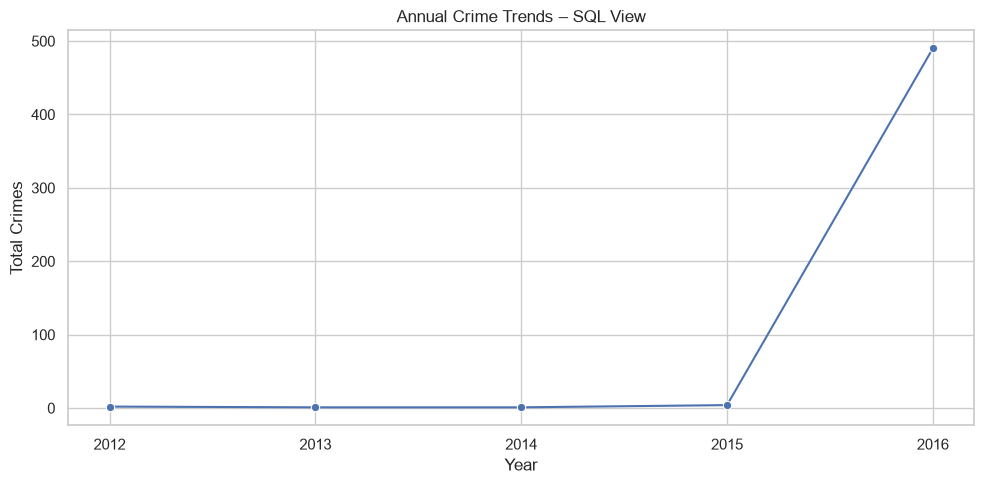

In [14]:
plt.figure(figsize=(10, 5))

sns.lineplot(
    data=yearly_view_df,
    x="Year",
    y="Total_Crimes",
    marker="o"
)

plt.title("Annual Crime Trends – SQL View")
plt.xlabel("Year")
plt.ylabel("Total Crimes")
plt.xticks(yearly_view_df["Year"])
plt.tight_layout()
plt.show()

Annual arrest rates from SQL view

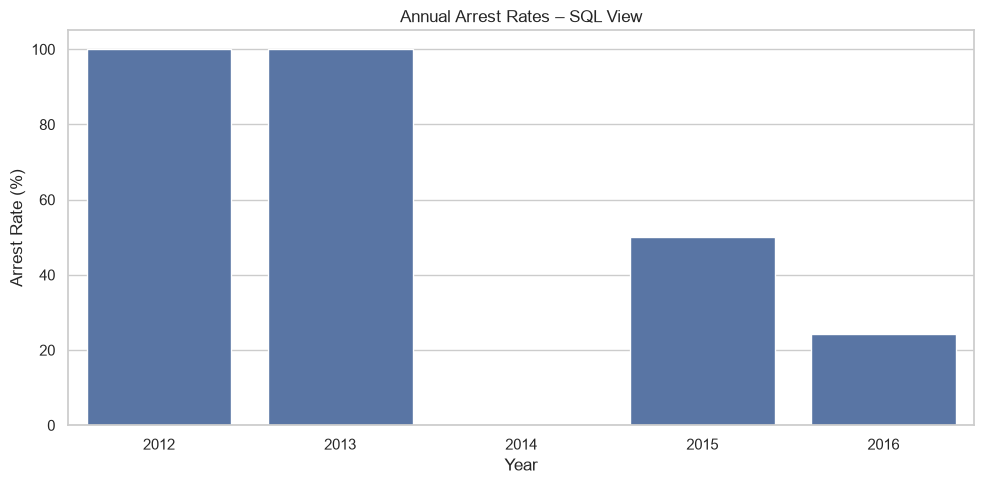

In [15]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=yearly_view_df,
    x="Year",
    y="Arrest_Rate"
)

plt.title("Annual Arrest Rates – SQL View")
plt.xlabel("Year")
plt.ylabel("Arrest Rate (%)")

plt.tight_layout()
plt.show()

Top 10 crime categories from SQL view

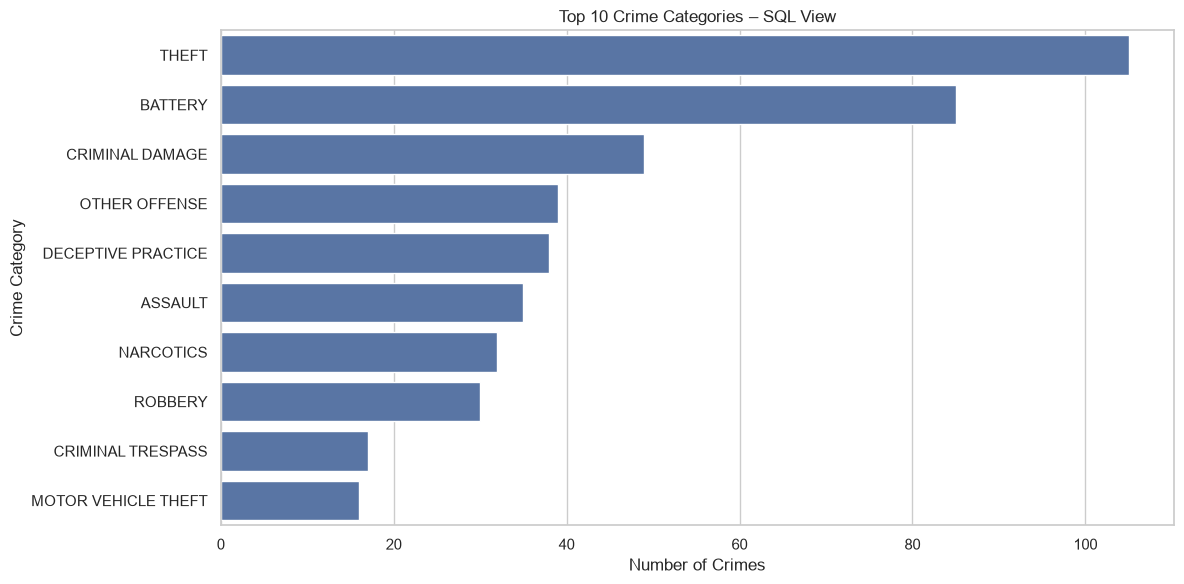

In [16]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=category_view_df,
    x="Crime_Count",
    y="Crime_Category"
)

plt.title("Top 10 Crime Categories – SQL View")
plt.xlabel("Number of Crimes")
plt.ylabel("Crime Category")

plt.tight_layout()
plt.show()

Save SQL analysis results and Close the database connection

In [18]:
REPORTS_DIR = PROJECT_DIR / "reports"
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

yearly_view_df.to_csv(
    REPORTS_DIR / "sql_yearly_crime_summary.csv",
    index=False
)

category_view_df.to_csv(
    REPORTS_DIR / "sql_crime_category_summary.csv",
    index=False
)

print("SQL analysis results saved successfully!")

connection.close()

print("SQLite connection closed successfully!")

SQL analysis results saved successfully!
SQLite connection closed successfully!
